# Diffusivity comparison between studies

Goal here is to compare the distribution of diffusivity estimates between my and Espe's estimates, and other papers using different methods. Cole, Groeskamp, Sevellec, Roach, etc

In [48]:
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.colors as colors
from matplotlib.cm import ScalarMappable
import cartopy.crs as ccrs
import cmocean.cm as cmo
import h5py
from scipy.io import loadmat

# Load Datasets

In [49]:
# my dataset
ds_pbar_grid = xr.open_dataset('/swot/SUM05/amf2288/ds_pbar_grid_var.nc')
ds_pbar_grad = xr.open_dataset('/swot/SUM05/amf2288/ds_pbar_grad_diff.nc')
ds_pbar_grid = ds_pbar_grid.assign_coords(LON_left = ds_pbar_grad.LON_left,LAT_left = ds_pbar_grad.LAT_left)
ds_amf = xr.merge([ds_pbar_grid, ds_pbar_grad.drop_vars({'DENSITY'})])

In [50]:
# espe's dataset
ds_eb = xr.open_dataset("/swot/SUM05/amf2288/argo_mixing/global_datasets_20261116/global_binned_3deg.nc", engine="netcdf4")

In [51]:
# Cole et al. (2015): promote the physical lon/lat variables to coordinates.
ds_Cole = xr.open_dataset('/swot/SUM05/amf2288/diff_comp/Cole2015_3deg.nc')
ds_Cole = ds_Cole.set_coords(['longitude', 'latitude']).swap_dims(
    {'lon': 'longitude', 'lat': 'latitude'}
)
ds_Cole = ds_Cole.assign_coords(
    longitude=(ds_Cole.longitude + 180) % 360 - 180
).sortby('longitude')

In [52]:
# Groeskamp et al. (2020): this MATLAB v7.3 file uses HDF5, not NetCDF.
# K_WOA is stored by h5py in (depth, latitude, longitude) order.
groeskamp_path = '/swot/SUM05/amf2288/diff_comp/Groeskamp2020_K.mat'
with h5py.File(groeskamp_path, 'r') as mat:
    woa = mat['WOA18_K']
    ds_Groeskamp = xr.Dataset(
        data_vars={
            'K_WOA': (
                ('depth', 'latitude', 'longitude'), woa['K_WOA'][()],
                {'units': 'm2 s-1', 'long_name': 'Groeskamp 2020 eddy diffusivity'},
            ),
        },
        coords={
            'depth': ('depth', woa['z'][()].ravel(), {'units': 'm', 'positive': 'down'}),
            'latitude': ('latitude', woa['y'][()].ravel(), {'units': 'degrees_north'}),
            'longitude': ('longitude', woa['x'][()].ravel(), {'units': 'degrees_east'}),
        },
        attrs={'source': groeskamp_path, 'matlab_variable': 'WOA18_K.K_WOA'},
    )
ds_Groeskamp = ds_Groeskamp.assign_coords(
    longitude=(ds_Groeskamp.longitude + 180) % 360 - 180
).sortby('longitude')

In [53]:
# Sevellec et al. (2022): horizontal tensor at approximately 1000 m.
ds_Sevellec = xr.open_dataset('/swot/SUM05/amf2288/diff_comp/Sevellec2022.nc')
ds_Sevellec = ds_Sevellec.rename({'lon': 'longitude', 'lat': 'latitude'}).expand_dims(
    depth=[1000.0]
)
ds_Sevellec.depth.attrs = {'units': 'm', 'positive': 'down', 'long_name': 'Nominal depth'}
# Scalar horizontal mean = half the tensor trace; retain all tensor components.
ds_Sevellec['diffusivity'] = (ds_Sevellec.kxx + ds_Sevellec.kyy) / 2
ds_Sevellec.diffusivity.attrs = {
    'units': 'm2 s-1',
    'long_name': 'Mean horizontal diffusivity (half the horizontal tensor trace)',
    'formula': '(kxx + kyy) / 2',
}

In [54]:
# Roach et al. (2018): combine surface and 1000-m MATLAB products.
# Surface is MATLAB v7.3/HDF5; 1000 m is MATLAB v5 with a different axis order.
roach_surface_path = '/swot/SUM05/amf2288/diff_comp/Roach2018_0.mat'
roach_deep_path = '/swot/SUM05/amf2288/diff_comp/Roach2018_1000.mat'
with h5py.File(roach_surface_path, 'r') as mat:
    roach_surface = xr.Dataset(
        data_vars={
            name: (('lag_day', 'latitude', 'longitude'), mat[source][()])
            for name, source in [
                ('Kcc', 'Kcc'), ('errKcc', 'errKcc'), ('Kac', 'Kac'),
                ('errKac', 'errKac'), ('num_pairs', 'num_pairs_t'),
                ('sumdXYsq', 'sumdXYsq'),
            ]
        },
        coords={
            'lag_day': mat['t_in'][()].ravel(),
            'latitude': mat['lat_bins'][()].ravel(),
            'longitude': mat['lon_bins'][()].ravel(),
        },
    )
    roach_surface['initial_num_pairs'] = (
        ('latitude', 'longitude'), mat['num_pairs'][()]
    )
roach_surface = roach_surface.expand_dims(depth=[0.0])

roach_mat = loadmat(roach_deep_path)
# The file omits time coordinates; the paper specifies 10-day Argo intervals.
roach_deep = xr.Dataset(
    data_vars={
        name: (('lag_day', 'latitude', 'longitude'), roach_mat[name].transpose(2, 1, 0))
        for name in ['Kcc', 'errKcc', 'num_pairs', 'sumdXYsq']
    },
    coords={
        'lag_day': 10.0 * np.arange(roach_mat['Kcc'].shape[2]),
        'latitude': roach_mat['y'].ravel(),
        'longitude': roach_mat['x'].ravel(),
    },
)
roach_deep['land_mask'] = (('latitude', 'longitude'), roach_mat['mask'].T)
roach_deep = roach_deep.expand_dims(depth=[1000.0])

# The two endpoint columns (-180 and +180) are identical in both source files.
# Keep -180 once for maps and histogram counts. No spatial interpolation.
roach_surface = roach_surface.sel(longitude=roach_surface.longitude < 180)
roach_deep = roach_deep.sel(longitude=roach_deep.longitude < 180)
ds_Roach = xr.concat([roach_surface, roach_deep], dim='depth', join='outer')
ds_Roach = ds_Roach.assign_coords(source_file=('depth', [roach_surface_path, roach_deep_path]))
ds_Roach.depth.attrs = {'units': 'm', 'positive': 'down', 'long_name': 'Nominal depth; 0 denotes surface product'}
ds_Roach.lag_day.attrs = {'units': 'days', 'long_name': 'Time since particle-pair release'}
ds_Roach.longitude.attrs = {'units': 'degrees_east'}
ds_Roach.latitude.attrs = {'units': 'degrees_north'}
for name in ['Kcc', 'errKcc', 'Kac', 'errKac']:
    ds_Roach[name].attrs['units'] = 'm2 s-1'
ds_Roach.Kcc.attrs['long_name'] = 'Cross-stream diffusivity at each time lag'

# Published averaging windows, inclusive: surface 10–50 d; 1000 m 100–200 d.
# Retain native Kcc and diagnostics; padded intermediate Argo lags remain NaN.
ds_Roach['averaging_start_day'] = ('depth', [10.0, 100.0])
ds_Roach['averaging_end_day'] = ('depth', [50.0, 200.0])
ds_Roach['required_lag_count'] = ('depth', [9, 11])
roach_window = (
    (ds_Roach.lag_day >= ds_Roach.averaging_start_day)
    & (ds_Roach.lag_day <= ds_Roach.averaging_end_day)
)
roach_window_values = ds_Roach.Kcc.where(roach_window & np.isfinite(ds_Roach.Kcc))
ds_Roach['averaging_lag_count'] = roach_window_values.count('lag_day')
# Require complete native-window coverage; respect the supplied deep land mask.
roach_valid = (ds_Roach.averaging_lag_count == ds_Roach.required_lag_count)
roach_valid = roach_valid & ((ds_Roach.depth == 0) | (ds_Roach.land_mask == 1))
ds_Roach['diffusivity'] = roach_window_values.mean('lag_day', skipna=True).where(roach_valid)
ds_Roach.diffusivity.attrs = {
    'units': 'm2 s-1', 'long_name': 'Time-mean cross-stream diffusivity',
    'averaging': 'Kcc mean over 10–50 days at surface and 100–200 days at 1000 m; complete native lag support',
    'quality_control': 'Supplied deep land mask; no additional pair-count or relative-error threshold',
    'reference': 'https://doi.org/10.1029/2018JC013750',
}
ds_Roach.attrs['surface_comparison'] = 'Surface product (nominal depth 0 m) displayed only in the 200 target panel; not a 200-m estimate'
ds_Roach.attrs['source_code_reference'] = 'https://github.com/croachutas/Isopycnal_Diffusivity/blob/master/read_viz_data.ipynb' 

# Compare diffusivities

Use the same eight target levels, Plate Carrée maps, `cmo.dense_r` colormap,
and logarithmic limits as `comp_diffusivity.ipynb`. Studies occupy rows and target
levels occupy columns. Unsupported study/level combinations have no map.

- **AMF:** use the original, unclipped CT/SA gradients and vertically filled
  `K_rho_filt_p.nc`, as in the reference notebook.
- **Espe:** use `KisoT_pressure` and `KisoS_pressure`.
- **Cole 2015:** use the supplied `diffusivity` field.
- **Groeskamp 2020:** use `WOA18_K.K_WOA`.
- **Sevellec 2022:** show only the nominal **1000 m** field. For this scalar
  comparison, use `(kxx + kyy) / 2` (half the horizontal tensor trace); retain
  the original tensor in `ds_Sevellec`.
- **Roach 2018:** combine both files in `ds_Roach`, retaining the native `Kcc`
  lag series and diagnostics. Average cross-stream diffusivity over **10–50 days
  at the surface** and **100–200 days at 1000 m**, using the windows in
  [Roach et al. (2018)](https://doi.org/10.1029/2018JC013750). The 1000-m file's
  omitted time coordinate is reconstructed at 10-day intervals, as described in
  the [authors' example](https://github.com/croachutas/Isopycnal_Diffusivity/blob/master/read_viz_data.ipynb).
  Require all native lags in the averaging window and apply the supplied deep
  land mask. Additional pair-count and relative-error thresholds are not applied.

**Roach's surface product is shown in the 200 target column for comparison;
it is not a measurement at 200 m.** Its other field appears only at 1000 m.
The dataset retains depths `[0, 1000]`; no 200-m data are fabricated.

AMF and Espe use **dbar**; the published depth products use **meters**. The first
four studies retain nearest-level selection, with actual levels labeled. The two
sparse products use explicit level assignments, with no depth extrapolation.
Any remaining time dimension is averaged before surface selection for both
maps and histograms. Roach uses the elapsed-lag windows documented above.
All maps retain native horizontal grids. The four published studies supply the
same reference fields in the CT and SA figures; CT/SA applies only to AMF and Espe.
Only finite positive values appear on the log scale. Empty supported levels are
labeled, including Espe at 1925 dbar.

In [55]:
# Edit (minimum, maximum) colorbar limits in m² s⁻¹; limits must be positive.
# Each tracer uses one log scale shared by all studies and all levels.
CT_DIFFUSIVITY_LIMITS = (1e1, 1e5)
SA_DIFFUSIVITY_LIMITS = (1e1, 1e5)
DIFFUSIVITY_CMAP = cmo.dense_r
depths = [200, 500, 750, 1000, 1250, 1500, 1700, 1900]

In [56]:
# Recalculate the canonical fields on every plot run, including in an old kernel.
# This uses the original gradient components, with no minimum gradient floor.
amf_krho = (
    xr.open_dataarray('/swot/SUM05/amf2288/K_rho_filt_p.nc')
    .drop_vars('Z').rename({'PRESSURE': 'PRESSURE_mean'})
    .bfill('PRESSURE_mean').ffill('PRESSURE_mean')
)
for tracer in ['CT', 'SA']:
    gradient_squared = ds_amf[f'd{tracer}_m_dx']**2 + ds_amf[f'd{tracer}_m_dy']**2
    denominator = gradient_squared.where(np.isfinite(gradient_squared) & (gradient_squared > 0))
    diffusivity = amf_krho * ds_amf[f'{tracer}_e_var'] / denominator
    ds_amf[f'K_e_{tracer}'] = diffusivity.where(np.isfinite(diffusivity))
    ds_amf[f'K_e_{tracer}'].attrs = {
        'units': 'm2 s-1',
        'long_name': f'Eddy diffusivity from {tracer}, using unclipped horizontal gradients',
        'formula': f'K_rho_p * {tracer}_e_var / (d{tracer}_m_dx**2 + d{tracer}_m_dy**2)',
        'gradient_floor': 'none; zero and nonfinite denominators are masked',
    }
    # Keep the earlier alias synchronized with the canonical field.
    ds_amf[f'K_e_{tracer}_unclipped'] = ds_amf[f'K_e_{tracer}']

In [57]:
# Shared field and depth selection for maps and histograms.
# Each tuple: name, field, vertical coordinate, unit, lon, lat, explicit levels.
def comparison_studies(tracer):
    espe_name = {'CT': 'KisoT_pressure', 'SA': 'KisoS_pressure'}[tracer]
    return [
        ('AMF', ds_amf[f'K_e_{tracer}'], 'PRESSURE_mean', 'dbar', 'LON', 'LAT', None),
        ('Espe', ds_eb[espe_name], 'pressure_bin', 'dbar', 'longitude', 'latitude', None),
        ('Cole 2015', ds_Cole.diffusivity, 'depth', 'm', 'longitude', 'latitude', None),
        ('Groeskamp 2020', ds_Groeskamp.K_WOA, 'depth', 'm', 'longitude', 'latitude', None),
        ('Sevellec 2022', ds_Sevellec.diffusivity, 'depth', 'm', 'longitude', 'latitude', {1000: 1000}),
        ('Roach 2018', ds_Roach.diffusivity, 'depth', 'm', 'longitude', 'latitude', {200: 0, 1000: 1000}),
    ]


def comparison_level(estimates, vertical, target_level, explicit_levels):
    # Average any remaining time dimension before selecting a map surface.
    # Roach's elapsed-lag mean is already prepared in ds_Roach.diffusivity.
    time_dims = [
        dim for dim in estimates.dims
        if dim.lower() in {'time', 'date', 'datetime', 'time_counter', 'lag_day'}
        or (dim in estimates.coords and (
            np.issubdtype(estimates[dim].dtype, np.datetime64)
            or estimates[dim].attrs.get('axis') == 'T'
            or estimates[dim].attrs.get('standard_name') == 'time'
        ))
    ]
    if time_dims:
        estimates = estimates.mean(time_dims, skipna=True, keep_attrs=True)
    if explicit_levels is None:
        return estimates.sel({vertical: target_level}, method='nearest')
    if target_level not in explicit_levels:
        return None
    return estimates.sel({vertical: explicit_levels[target_level]})


def comparison_level_label(study, level, unit):
    if study == 'Roach 2018' and level == 0:
        return 'surface (0 m)*'
    return f'{level:g} {unit}'


ROACH_SURFACE_NOTE = '* Roach surface estimates are shown in the 200 panel; they are not estimates at 200 m.'

In [58]:
# Actual levels used in each column; em dash means the study is absent.
selected_levels = pd.DataFrame({'Target level': depths})
for study, estimates, vertical, unit, lon, lat, explicit_levels in comparison_studies('CT'):
    actual_levels = []
    for depth in depths:
        field = comparison_level(estimates, vertical, depth, explicit_levels)
        actual_levels.append(
            '—' if field is None else comparison_level_label(study, float(field[vertical]), unit)
        )
    selected_levels[study] = actual_levels
selected_levels

,Target level,AMF,Espe,Cole 2015,Groeskamp 2020,Sevellec 2022,Roach 2018
0,200,200 dbar,225 dbar,200 m,200 m,—,surface (0 m)*
1,500,500 dbar,525 dbar,500 m,500 m,—,—
2,750,750 dbar,775 dbar,760 m,750 m,—,—
3,1000,1000 dbar,1025 dbar,1000 m,1000 m,1000 m,1000 m
4,1250,1250 dbar,1275 dbar,1260 m,1250 m,—,—
5,1500,1500 dbar,1525 dbar,1500 m,1500 m,—,—
6,1700,1700 dbar,1725 dbar,1700 m,1700 m,—,—
7,1900,1900 dbar,1925 dbar,1900 m,1900 m,—,—


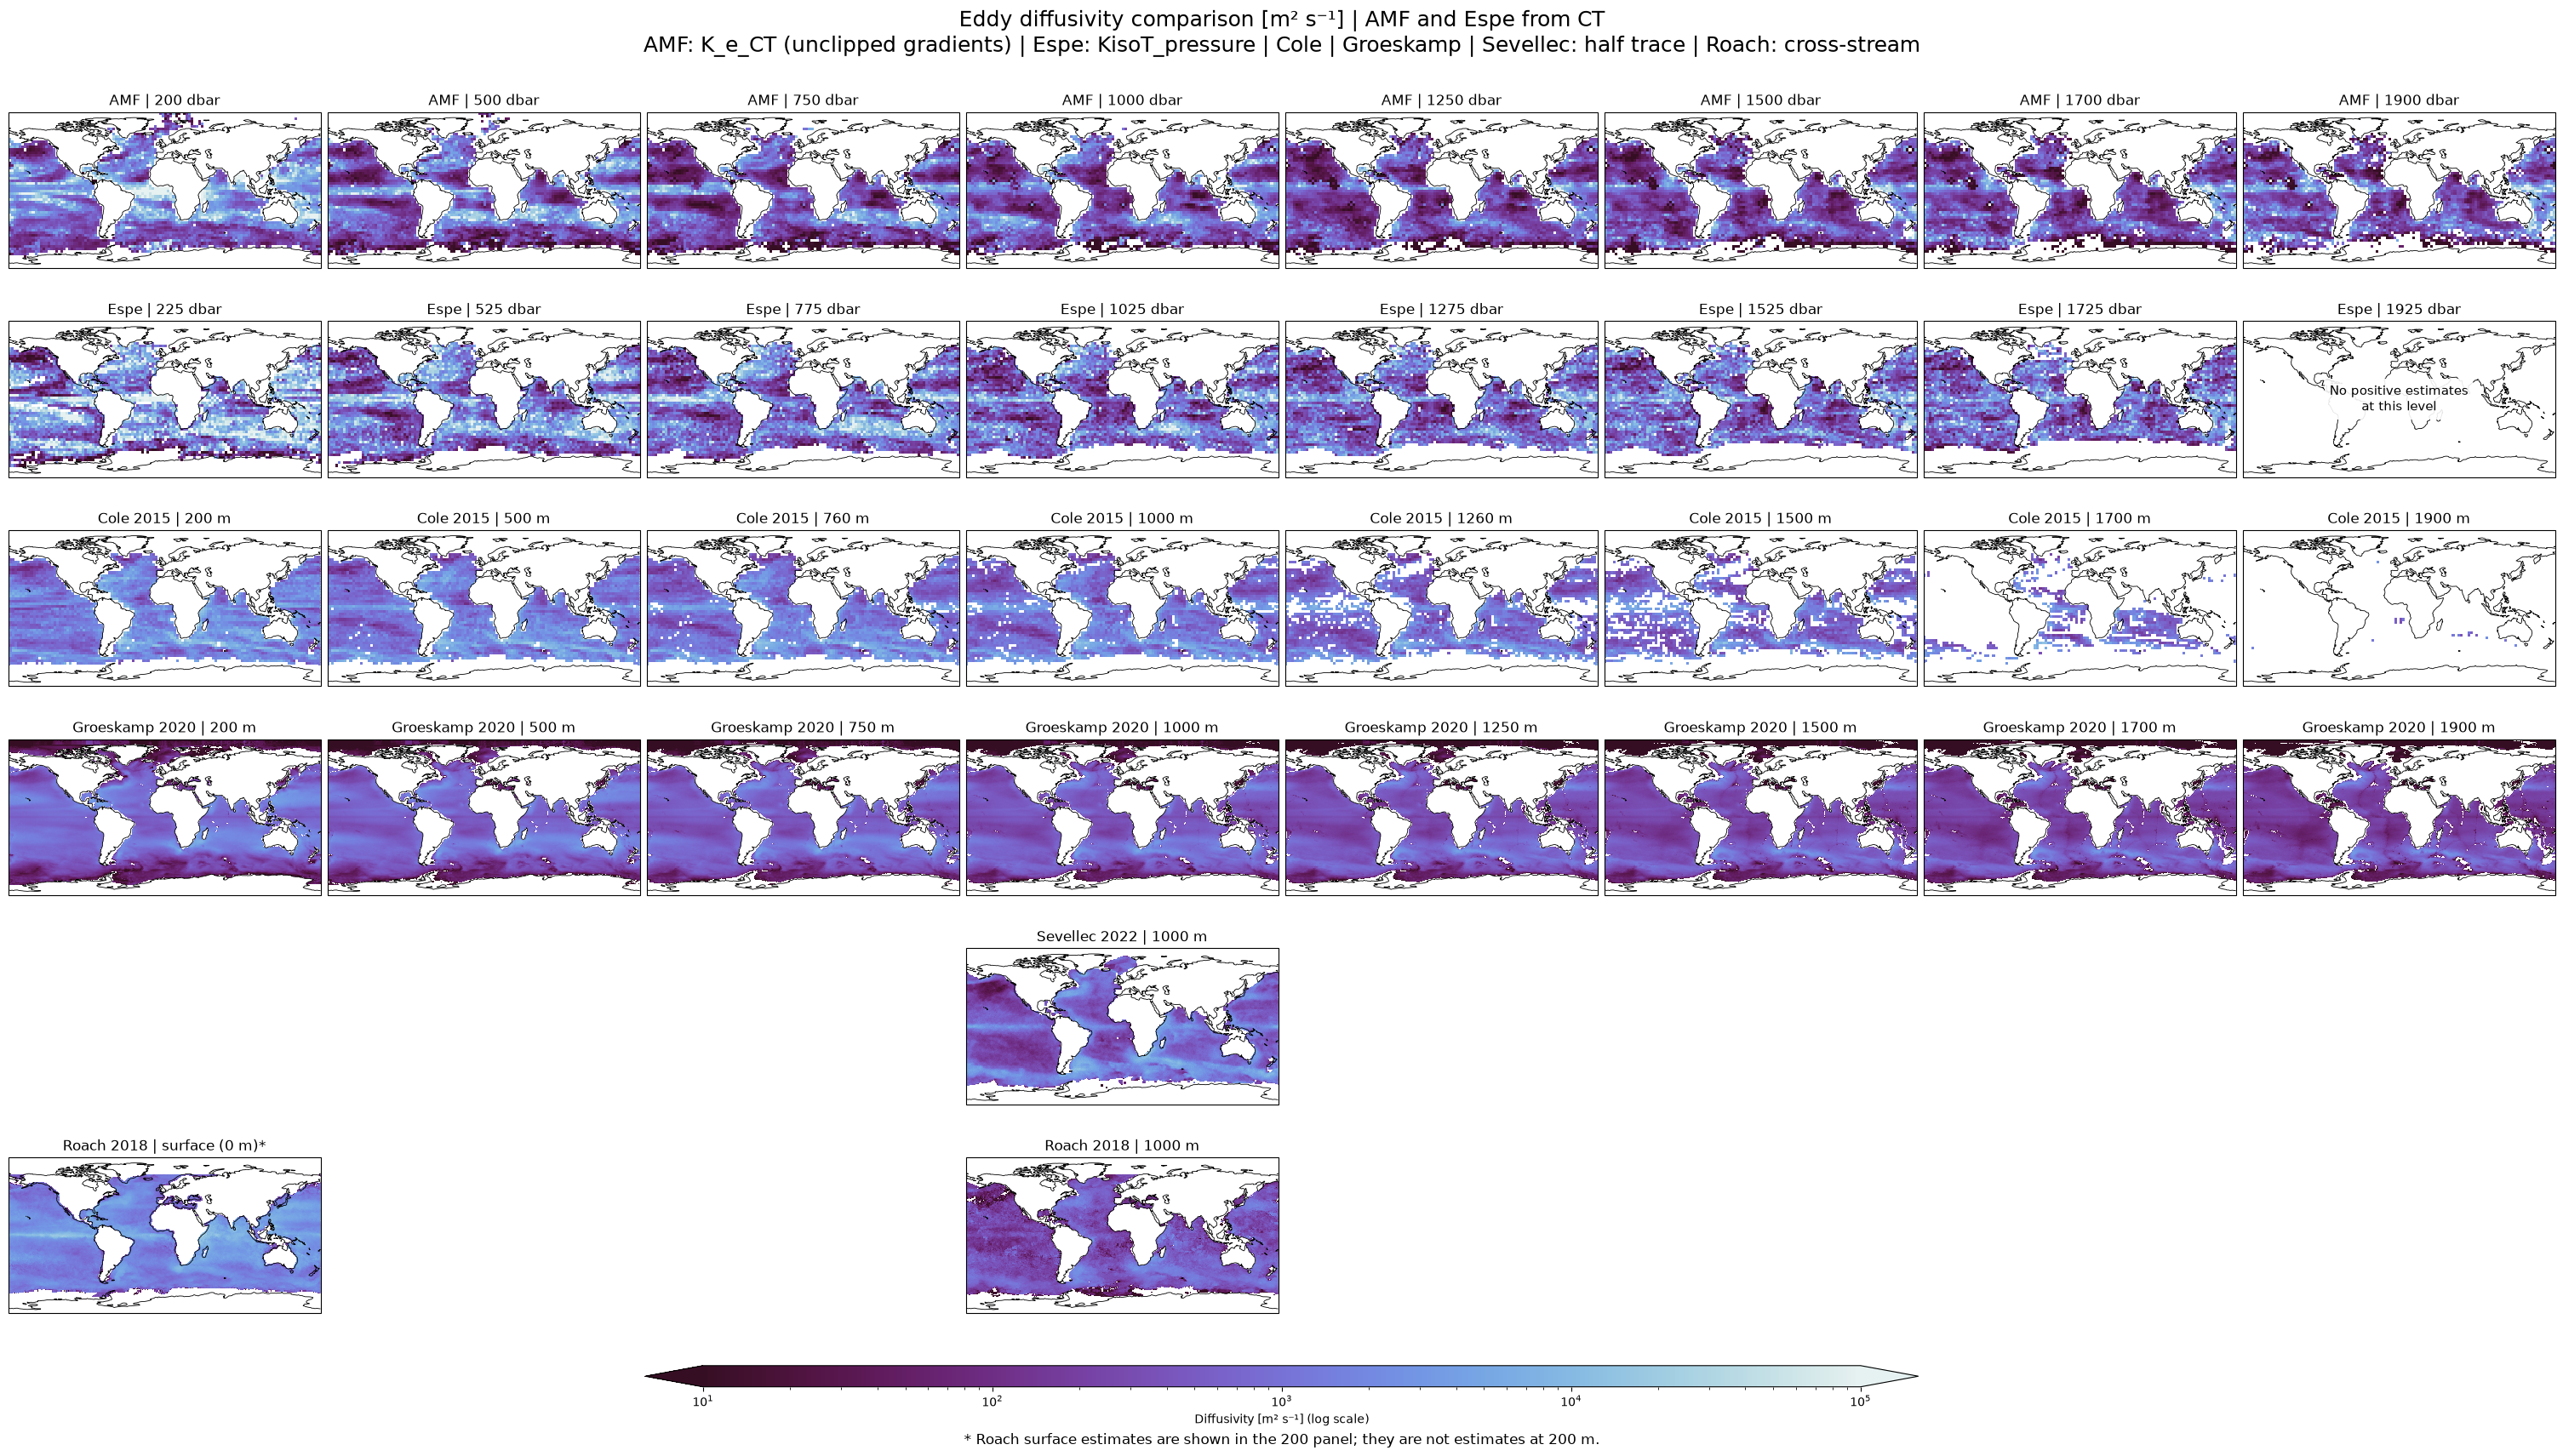

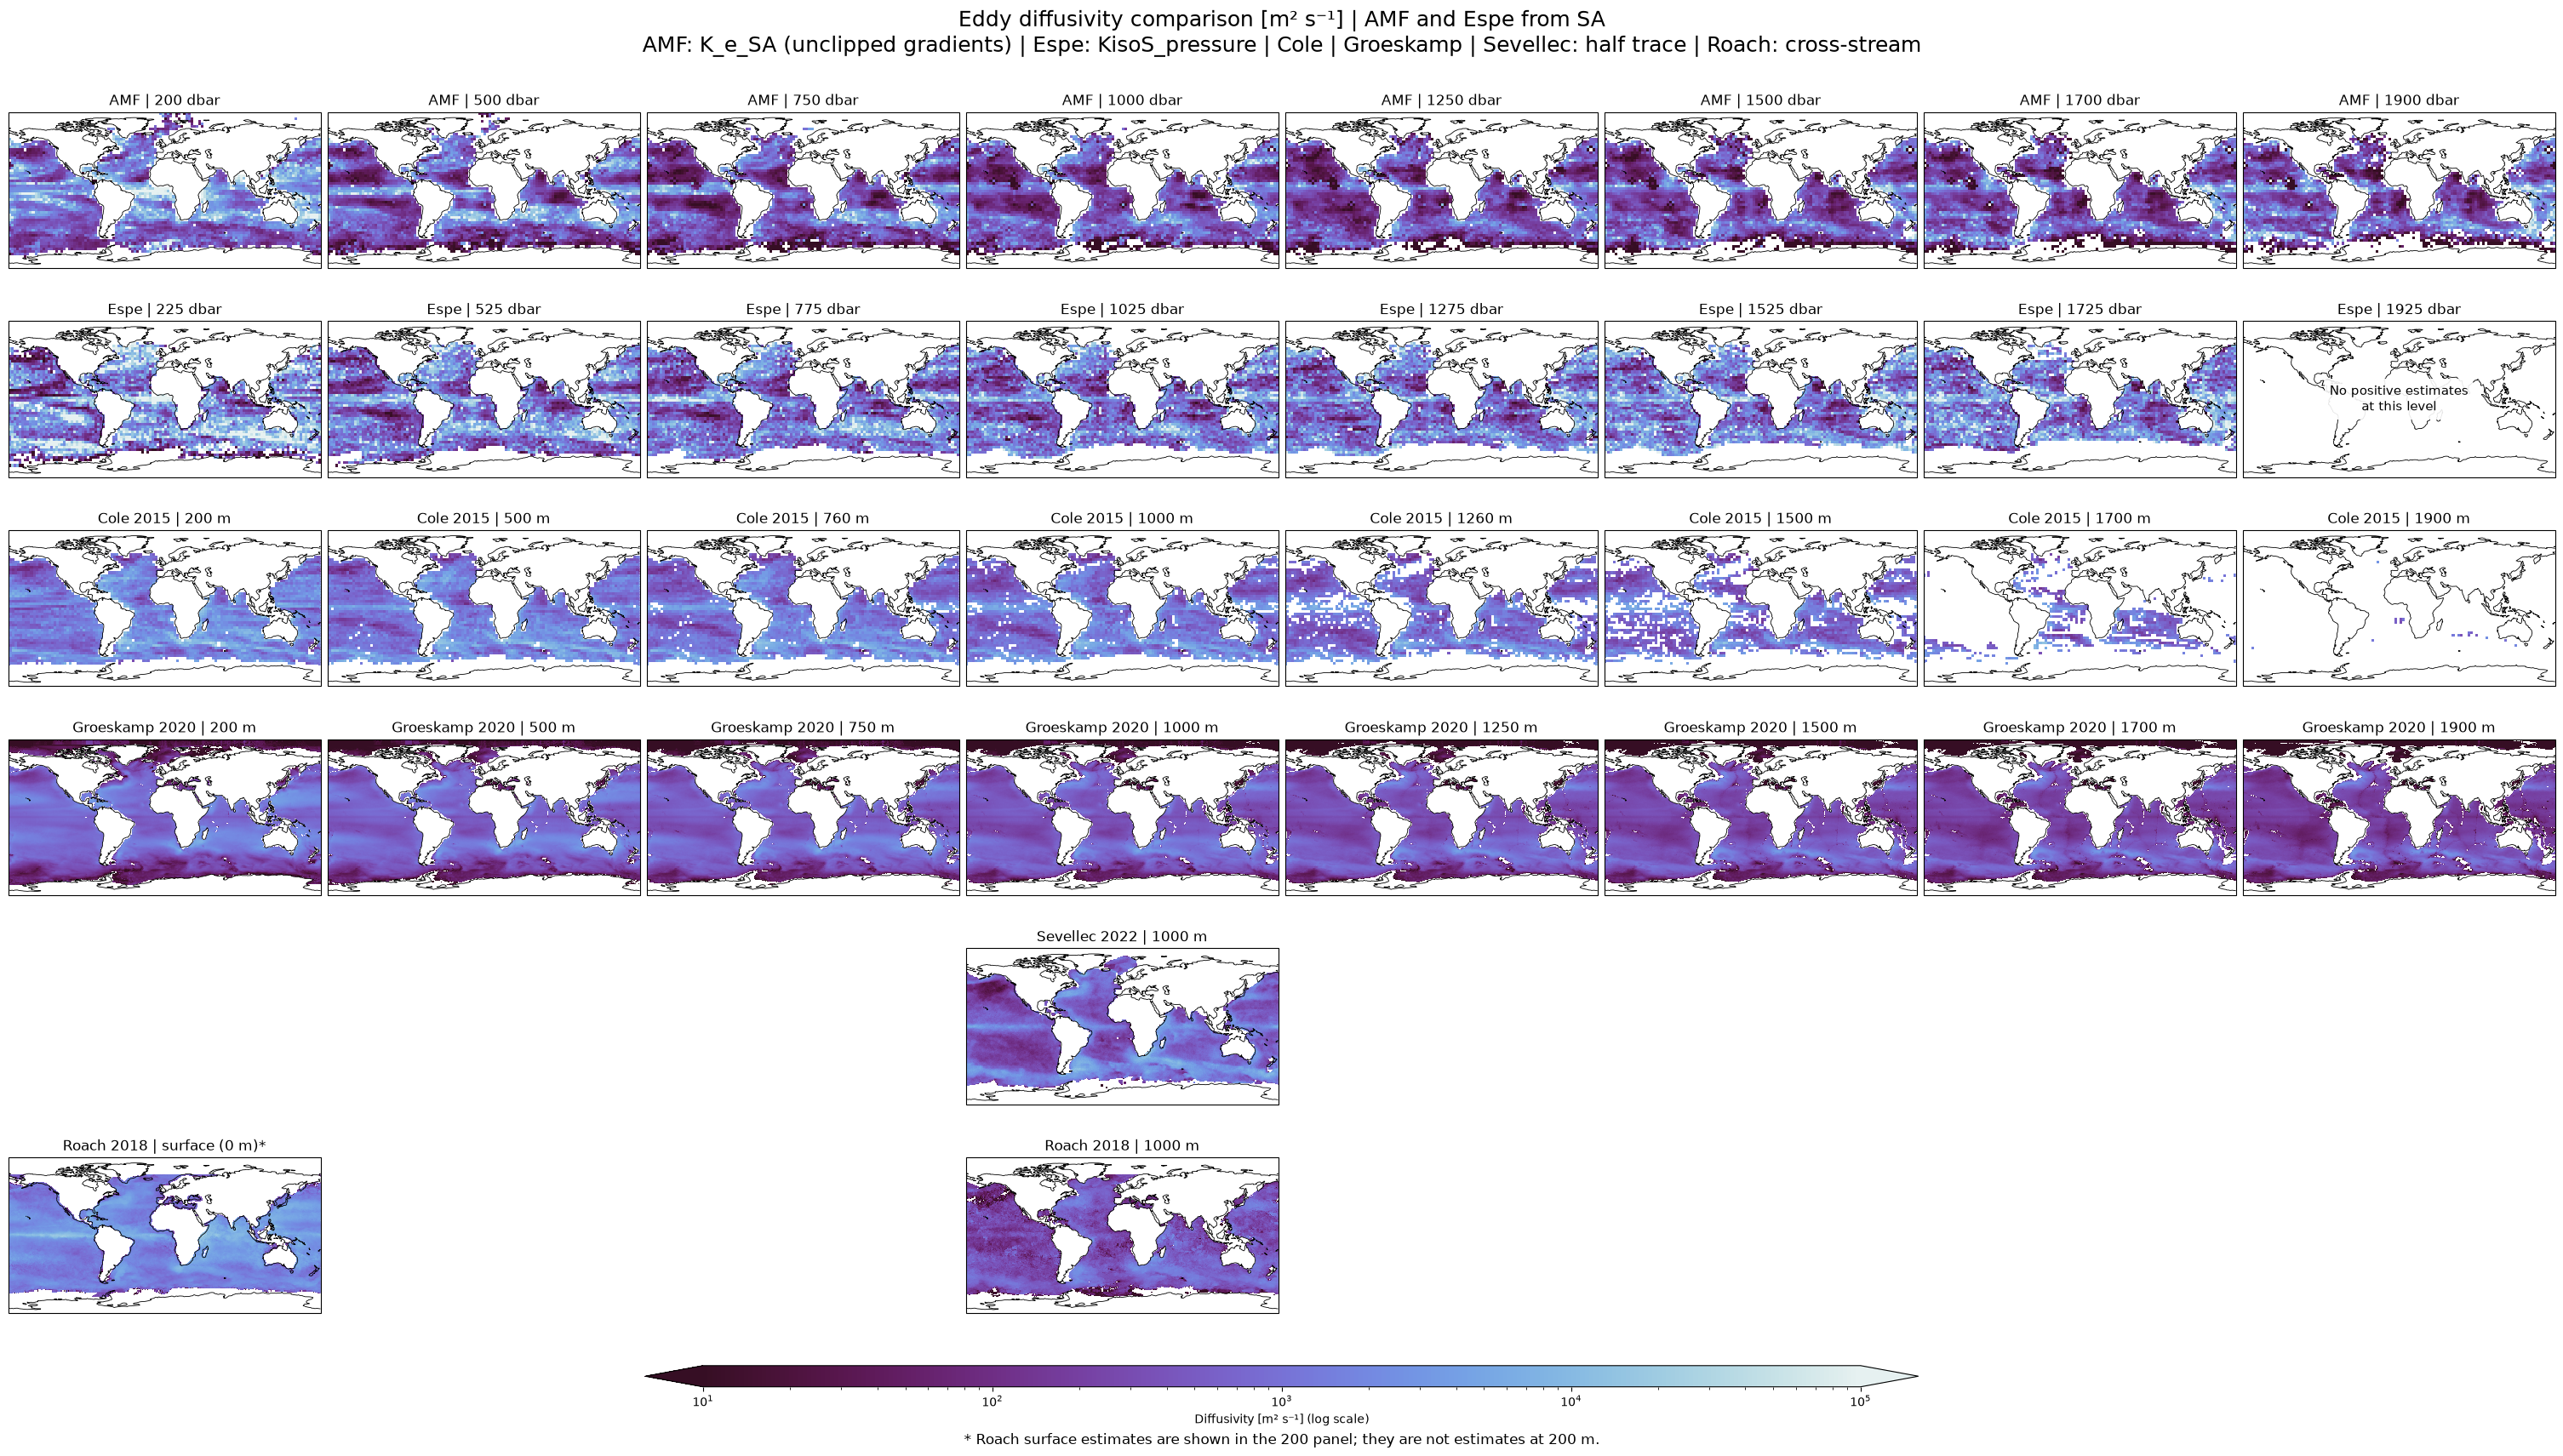

In [59]:
# One comparison for CT and one for SA; sparse studies appear only at supported levels.
# Published fields are the same reference estimates in both figures.
# Close only this cell's earlier figures when rerunning it.
for previous_figure in globals().get('diffusivity_figures', {}).values():
    plt.close(previous_figure)
diffusivity_figures = {}
diffusivity_axes = {}

for tracer, amf_name, espe_name, limits in [
    ('CT', 'K_e_CT', 'KisoT_pressure', CT_DIFFUSIVITY_LIMITS),
    ('SA', 'K_e_SA', 'KisoS_pressure', SA_DIFFUSIVITY_LIMITS),
]:
    if not (0 < limits[0] < limits[1]):
        raise ValueError(f'{tracer} color limits must satisfy 0 < minimum < maximum.')
    diffusivity_norm = colors.LogNorm(vmin=limits[0], vmax=limits[1])
    diffusivity_ticks = np.geomspace(*limits, 5)
    studies = comparison_studies(tracer)
    visible_axes = []
    fig, axes = plt.subplots(
        len(studies), len(depths), figsize=(30, 17), squeeze=False,
        subplot_kw={'projection': ccrs.PlateCarree()},
        constrained_layout=True,
    )
    fig.suptitle(
        f'Eddy diffusivity comparison [m² s⁻¹] | AMF and Espe from {tracer}\n'
        f'AMF: {amf_name} (unclipped gradients) | Espe: {espe_name} | '
        'Cole | Groeskamp | Sevellec: half trace | Roach: cross-stream',
        fontsize=18,
    )
    for row, (study, estimates, vertical, unit, lon, lat, explicit_levels) in enumerate(studies):
        for col, depth in enumerate(depths):
            ax = axes[row, col]
            field = comparison_level(estimates, vertical, depth, explicit_levels)
            if field is None:
                ax.set_visible(False)
                continue
            visible_axes.append(ax)
            actual_level = float(field[vertical])
            # Preserve the source values; mask only the field being plotted.
            field = field.where(np.isfinite(field) & (field > 0))
            if bool(field.notnull().any()):
                field.plot.pcolormesh(
                    ax=ax, x=lon, y=lat, transform=ccrs.PlateCarree(),
                    cmap=DIFFUSIVITY_CMAP, norm=diffusivity_norm, add_colorbar=False,
                )
            else:
                ax.text(
                    0.5, 0.5, 'No positive estimates\nat this level',
                    transform=ax.transAxes, ha='center', va='center', fontsize=11,
                    bbox={'facecolor': 'white', 'alpha': 0.9, 'edgecolor': 'none'},
                    zorder=5,
                )
            ax.set_global()
            ax.coastlines(resolution='110m', linewidth=0.6)
            level_label = comparison_level_label(study, actual_level, unit)
            ax.set_title(f'{study} | {level_label}', fontsize=12)

    fig.colorbar(
        ScalarMappable(norm=diffusivity_norm, cmap=DIFFUSIVITY_CMAP),
        ax=visible_axes, orientation='horizontal',
        fraction=0.04, pad=0.04, shrink=0.5, aspect=60,
        ticks=diffusivity_ticks, extend='both',
        label='Diffusivity [m² s⁻¹] (log scale)',
    )
    fig.supxlabel(ROACH_SURFACE_NOTE, fontsize=12)
    diffusivity_figures[tracer] = fig
    diffusivity_axes[tracer] = axes

plt.show()

## Distributions on the same depth surfaces

Two figures show **CT** and **SA**, each with one histogram subplot per target
level in `histogram_depths` (the map levels with **1900 omitted**). The same
study fields and nearest native levels used in the maps are selected here; legends report the actual level and the number of
finite, positive cells (`n`). The published studies are repeated reference estimates in both figures.
Sevellec is included only at 1000 m; Roach only at 200 (surface) and 1000 m.
**Roach at the 200 target level uses the surface product, not a 200-m estimate.**

All studies, depths, and tracers share logarithmically spaced bins covering the
full finite, positive data range. **`CT_HISTOGRAM_XLIM` and `SA_HISTOGRAM_XLIM`**
in the histogram settings cell control the visible range for each figure. These
limits zoom the axes without changing the bins or renormalizing the percentages.
The y-axis is **percentage of a study's finite, positive grid cells per bin**;
each full histogram sums to 100%, including bins outside the visible range. Each study uses its own native spatial
coverage with equal weight per grid cell. This normalization accounts for the
different numbers of grid cells; it does not area-weight or restrict studies to
a common spatial footprint. Empty distributions are labeled in the legend.

In [60]:
# Ten equal-width bins per decade (0.1 dex); shared across both figures.
HISTOGRAM_BINS_PER_DECADE = 10
HISTOGRAM_COLORS = {
    'AMF': 'tab:red',
    'Espe': 'tab:orange',
    'Cole 2015': 'tab:blue',
    'Groeskamp 2020': 'tab:green',
    'Sevellec 2022': 'tab:purple',
    'Roach 2018': 'tab:brown',
}

In [61]:
# Histogram x-axis limits (minimum, maximum), in m² s⁻¹.
# Edit these, then rerun this cell and the histogram plotting cell.
CT_HISTOGRAM_XLIM = (1e0, 1e6)
SA_HISTOGRAM_XLIM = (1e0, 1e6)
# These zoom the display; percentages still use all finite, positive cells.

In [62]:
# Use the same nearest-level fields as the maps, omitting 1900 in histograms.
histogram_depths = [depth for depth in depths if depth != 1900]
histogram_samples = {}
for tracer in ['CT', 'SA']:
    for study, estimates, vertical, unit, lon, lat, explicit_levels in comparison_studies(tracer):
        for depth in histogram_depths:
            field = comparison_level(estimates, vertical, depth, explicit_levels)
            if field is None:
                continue
            values = field.values.ravel()
            histogram_samples[tracer, study, depth] = {
                'values': values[np.isfinite(values) & (values > 0)],
                'level': float(field[vertical]),
                'unit': unit,
                'level_label': comparison_level_label(study, float(field[vertical]), unit),
            }

# Include the tails instead of truncating to the map colorbar limits.
nonempty_samples = [sample['values'] for sample in histogram_samples.values()
                    if sample['values'].size]
if not nonempty_samples:
    raise ValueError('No finite, positive diffusivities at the selected levels.')
log_min = np.floor(np.log10(min(values.min() for values in nonempty_samples)))
log_max = np.ceil(np.log10(max(values.max() for values in nonempty_samples)))
log_max = max(log_max, log_min + 1)
histogram_bins = np.logspace(
    log_min, log_max, int((log_max - log_min) * HISTOGRAM_BINS_PER_DECADE) + 1,
)

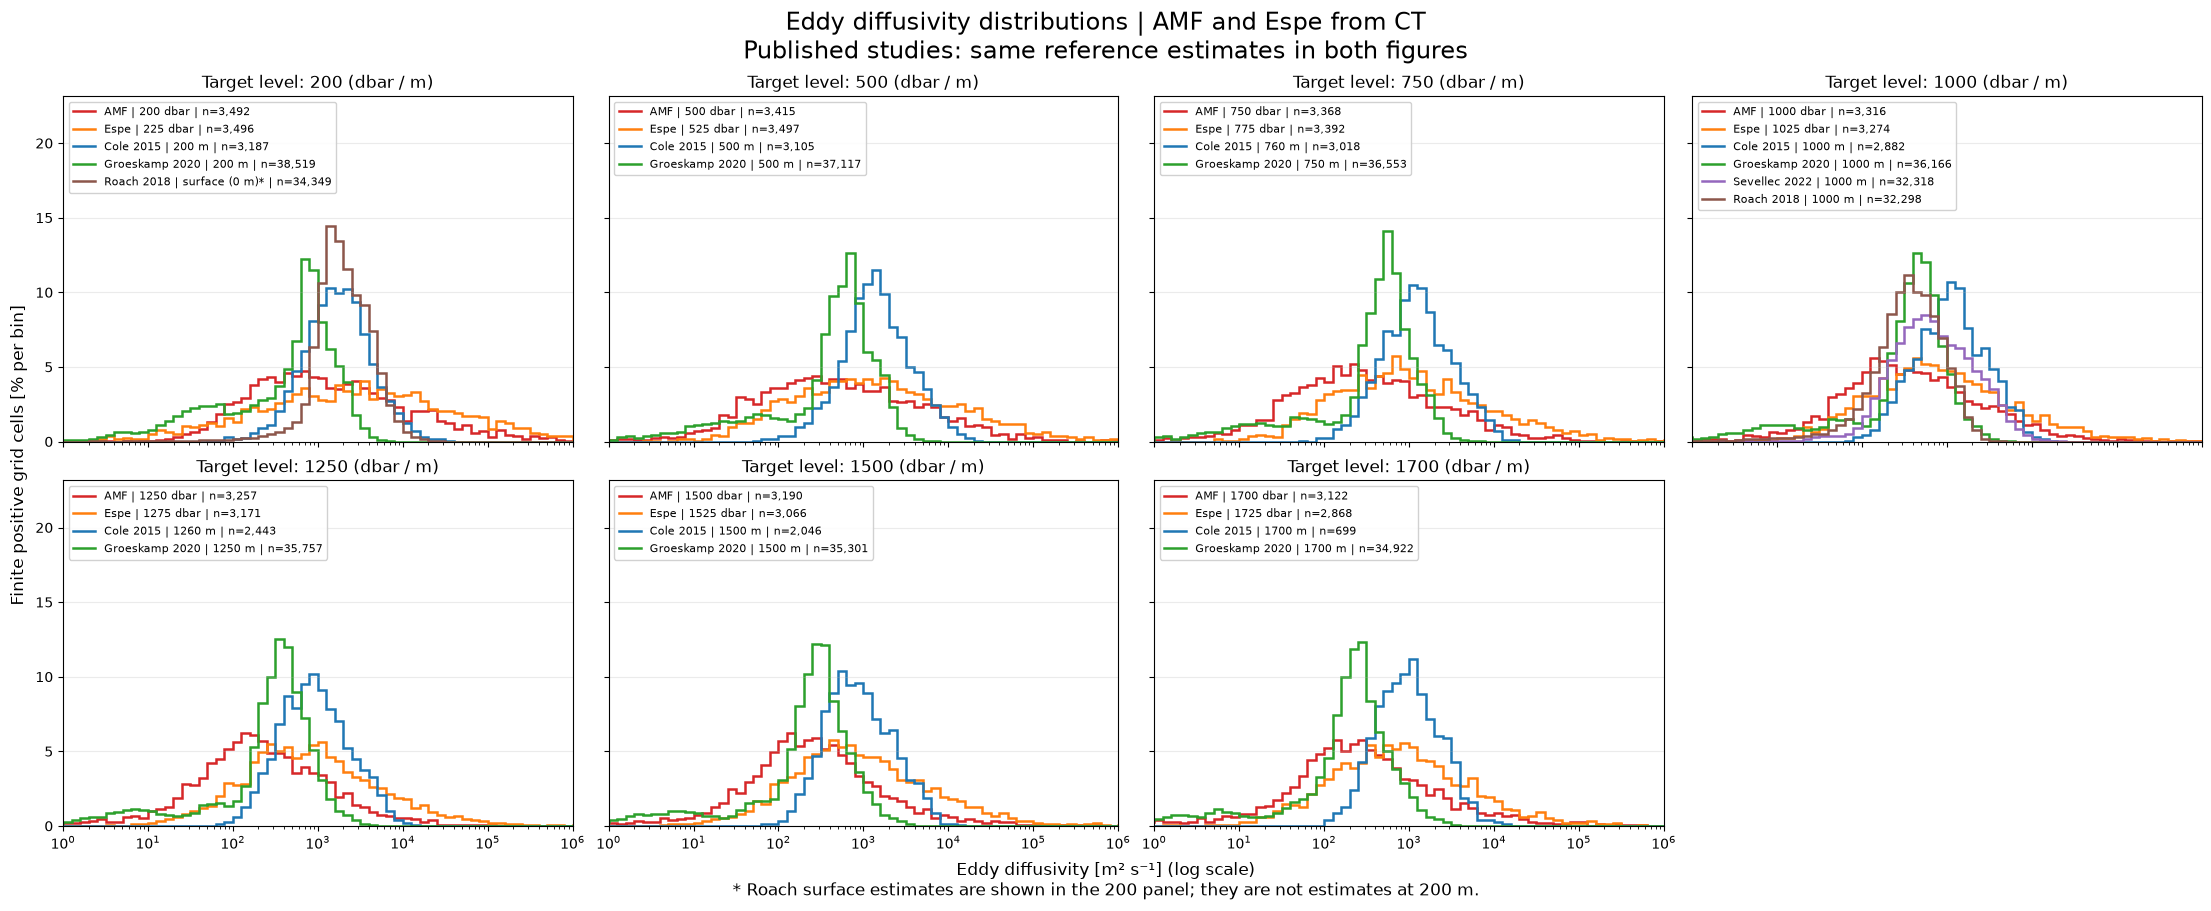

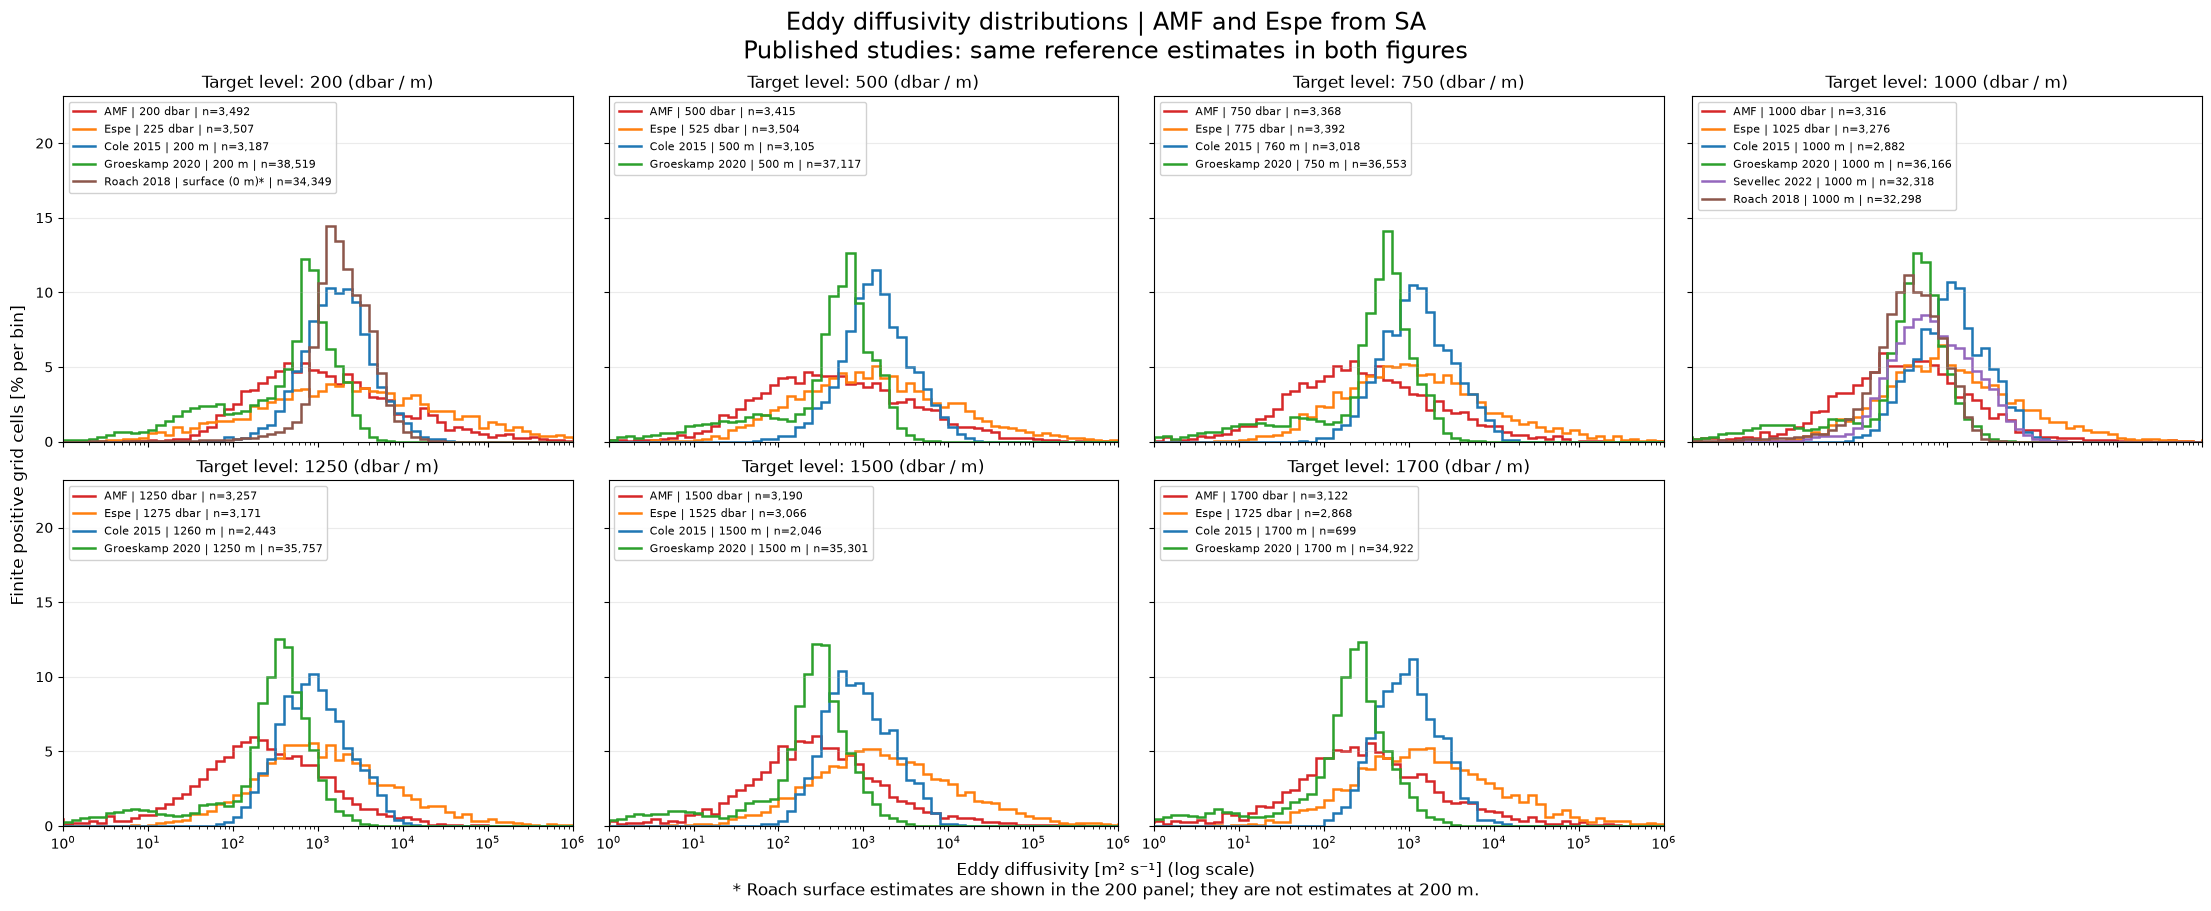

In [63]:
# Overlay the available studies at each depth; retain the figures for export.
for previous_figure in globals().get('histogram_figures', {}).values():
    plt.close(previous_figure)
histogram_figures = {}
histogram_axes = {}
histogram_percentages = {}

for tracer, xlimits in [('CT', CT_HISTOGRAM_XLIM), ('SA', SA_HISTOGRAM_XLIM)]:
    if not (np.all(np.isfinite(xlimits)) and 0 < xlimits[0] < xlimits[1]):
        raise ValueError(f'{tracer} histogram x-limits must be finite and satisfy 0 < minimum < maximum.')
    ncols = 4
    nrows = int(np.ceil(len(histogram_depths) / ncols))
    fig, axes = plt.subplots(
        nrows, ncols, figsize=(22, 4.5 * nrows), squeeze=False,
        sharex=True, sharey=True, constrained_layout=True,
    )
    fig.suptitle(
        f'Eddy diffusivity distributions | AMF and Espe from {tracer}\n'
        'Published studies: same reference estimates in both figures',
        fontsize=17,
    )
    for ax, depth in zip(axes.flat, histogram_depths):
        for study, color in HISTOGRAM_COLORS.items():
            sample = histogram_samples.get((tracer, study, depth))
            if sample is None:
                continue
            values = sample['values']
            label = f"{study} | {sample['level_label']}"
            if values.size:
                counts, _ = np.histogram(values, bins=histogram_bins)
                percentages = 100 * counts / values.size
                histogram_percentages[tracer, study, depth] = percentages
                ax.stairs(
                    percentages, histogram_bins, color=color, linewidth=1.8,
                    label=f'{label} | n={values.size:,}',
                )
            else:
                # A legend entry records missing data without drawing a zero curve.
                ax.plot([], [], color=color, linewidth=1.8,
                        label=f'{label} | no positive data (n=0)')
        ax.set_title(f'Target level: {depth:g} (dbar / m)', fontsize=12)
        ax.set_xscale('log')
        ax.set_xlim(*xlimits)
        ax.set_ylim(bottom=0)
        ax.grid(axis='y', alpha=0.25)
        ax.legend(loc='upper left', fontsize=8, framealpha=0.9)
    for ax in list(axes.flat)[len(histogram_depths):]:
        ax.set_visible(False)
    fig.supxlabel('Eddy diffusivity [m² s⁻¹] (log scale)\n' + ROACH_SURFACE_NOTE, fontsize=12)
    fig.supylabel('Finite positive grid cells [% per bin]', fontsize=12)
    histogram_figures[tracer] = fig
    histogram_axes[tracer] = axes

# One y-axis scale across both tracers; leave room for six-entry legends.
histogram_ymax = 1.6 * max(values.max() for values in histogram_percentages.values())
for axes in histogram_axes.values():
    for ax in axes.flat:
        ax.set_ylim(0, histogram_ymax)
plt.show()